In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/malvinm01/kmeans-gridsearch-results/kmeans_hyperparameter_results.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/sample_submission.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/imdb_data.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/genome_scores.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv
/kaggle/input/competitions/movie-recommendation-hackathon-2026/links.csv


In [3]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import root_mean_squared_error
from sklearn.mixture import GaussianMixture

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/train.csv')

train_df.head()

,userId,movieId,rating,timestamp
0,5163,57669,4.0,1518349992
1,106343,5,4.5,1206238739
2,146790,5459,5.0,1076215539
3,106362,32296,2.0,1423042565
4,9041,366,3.0,833375837


In [5]:
test_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/test.csv')

test_df.head()

,userId,movieId
0,1,2011
1,1,4144
2,1,5767
3,1,6711
4,1,7318


In [6]:
movies_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/movies.csv')

movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
tags_df = pd.read_csv('/kaggle/input/competitions/movie-recommendation-hackathon-2026/tags.csv')

tags_df.head()

,userId,movieId,tag,timestamp
0,3,260,classic,1439472355
1,3,260,sci-fi,1439472256
2,4,1732,dark comedy,1573943598
3,4,1732,great dialogue,1573943604
4,4,7569,so bad it's good,1573943455


## Content-Based Filtering approach using an Unsupervised Learning approach (KMeans)

In [8]:
merged_df = train_df.merge(
    movies_df,
    on='movieId',
    how='inner'
)

merged_df.head()

,userId,movieId,rating,timestamp,title,genres
0,5163,57669,4.0,1518349992,In Bruges (2008),Comedy|Crime|Drama|Thriller
1,106343,5,4.5,1206238739,Father of the Bride Part II (1995),Comedy
2,146790,5459,5.0,1076215539,Men in Black II (a.k.a. MIIB) (a.k.a. MIB 2) (...,Action|Comedy|Sci-Fi
3,106362,32296,2.0,1423042565,Miss Congeniality 2: Armed and Fabulous (2005),Adventure|Comedy|Crime
4,9041,366,3.0,833375837,Wes Craven's New Nightmare (Nightmare on Elm S...,Drama|Horror|Mystery|Thriller


In [9]:
# Split genres into individual categories
genres = movies_df['genres'].str.split('|')

# Initialize encoder
mlb = MultiLabelBinarizer()

# Transform genres into numerical features
genre_matrix = mlb.fit_transform(genres)

# Create a Dataframe
genre_df = pd.DataFrame(
    genre_matrix,
    columns=mlb.classes_,
    index=movies_df.index
)

genre_df

,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62418,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
62419,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
62420,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0
62421,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [10]:
movie_features = pd.concat(
    [
        movies_df[['movieId']].reset_index(drop=True),
        genre_df.reset_index(drop=True)
    ],
    axis=1
)

movie_features

,movieId,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,0,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,4,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0
4,5,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62418,209157,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
62419,209159,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
62420,209163,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
62421,209169,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
X = movie_features.drop(columns=['movieId'])

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)

kmeans.fit(X)

KMeans(n_clusters=10, n_init=10, random_state=42)

In [12]:
movie_features['cluster'] = kmeans.labels_

In [13]:
movie_features.head()

,movieId,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,cluster
0,1,0,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,7
1,2,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7
2,3,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3,4,0,0,0,0,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,5
4,5,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
user_movie_clusters = train_df.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

user_movie_clusters

,userId,movieId,rating,timestamp,cluster
0,5163,57669,4.0,1518349992,4
1,106343,5,4.5,1206238739,0
2,146790,5459,5.0,1076215539,6
3,106362,32296,2.0,1423042565,0
4,9041,366,3.0,833375837,4
...,...,...,...,...,...
10000033,136395,99114,5.0,1521235092,6
10000034,140078,553,3.0,1002580977,6
10000035,154807,56782,4.0,1227674807,1
10000036,85805,327,4.0,1479921530,6


In [15]:
user_cluster_preferences = (
    user_movie_clusters.groupby(['userId', 'cluster'])['rating']
    .mean().reset_index()
)

user_cluster_preferences.head()

,userId,cluster,rating
0,1,0,3.875000
1,1,1,3.875000
2,1,4,5.000000
3,1,5,3.666667
4,2,0,4.166667


In [16]:
inertia = []

for k in range(2, 20):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

# plt.figure(figsize=(10, 5))
# plt.plot(range(2, 20), inertia, marker='o')
# plt.xlabel('Number of Clusters (K)')
# plt.ylabel('Inertia')
# plt.title('Elbow Method')
# plt.xticks(range(2, 20))
# plt.grid()
# plt.show()

In [17]:
silhouette_scores = []

for k in range(2, 20):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

# plt.figure(figsize=(10, 5))
# plt.plot(range(2, 50), silhouette_scores, marker='o')
# plt.xlabel('Number of Clusters (K)')
# plt.ylabel('Silhouette Score')
# plt.title('Silhouette Analysis')
# plt.xticks(range(2, 50))
# plt.grid()
# plt.show()

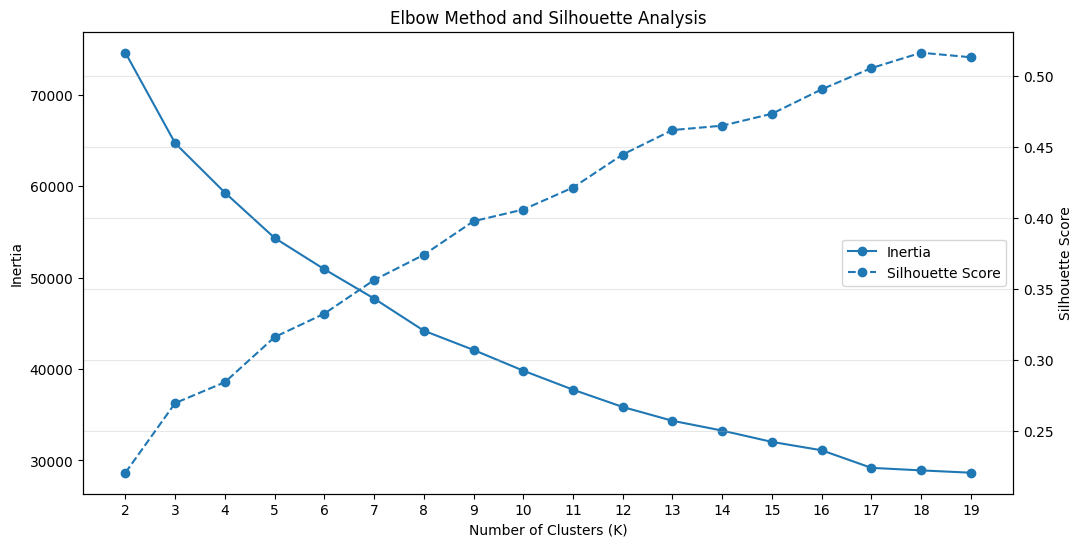

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot inertia
ax1.plot(
    range(2, 20),
    inertia,
    marker='o',
    label='Inertia'
)

ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia')
ax1.set_xticks(range(2, 20))

# Create a secondary y-axis
ax2 = ax1.twinx()

# PLot silhouette scores
ax2.plot(
    range(2, 20),
    silhouette_scores,
    marker='o',
    linestyle='--',
    label='Silhouette Score'
)

ax2.set_ylabel('Silhouette Score')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='center right'
)

plt.title('Elbow Method and Silhouette Analysis')
plt.grid(alpha=0.3)
plt.show()

In [19]:
chosen_k = 6

final_kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

movie_features['cluster'] = kmeans.fit_predict(X)

In [20]:
user_movie_clusters = train_df.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

user_movie_clusters.head()

,userId,movieId,rating,timestamp,cluster
0,5163,57669,4.0,1518349992,9
1,106343,5,4.5,1206238739,4
2,146790,5459,5.0,1076215539,1
3,106362,32296,2.0,1423042565,4
4,9041,366,3.0,833375837,11


In [21]:
user_cluster_preferences = (
    user_movie_clusters.groupby(['userId', 'cluster'])['rating']
    .mean().reset_index()
)

user_cluster_preferences.head(10)

,userId,cluster,rating
0,1,0,3.500000
1,1,2,3.950000
2,1,4,3.000000
3,1,8,4.166667
4,1,9,5.000000
5,1,12,3.375000
6,1,15,3.833333
7,1,18,4.500000
8,2,0,3.300000
9,2,1,3.038462


In [22]:
def predict_rating(
    user_id,
    movie_id,
    user_cluster_preferences,
    movie_features,
    train_df
):
    """
    This function is meant to predict how a particular user might rate
    a particular movie based on how they have rated other movied belonging
    to the same cluster

    Parameters:
        user_id - The user whose rating we want to predict
        movie_id - The movie the user hasn't rated yet
        user_cluster_preferences - Contains each user's average rating for each cluster
        movie_features - Contains movie features and their assigned cluster labels
        train_df - Contains the training ratings
    """
    '''Step One: Check whether the user exists in training data'''
    if user_id not in train_df['userId'].values:
        return train_df['rating'].mean()

    '''Step Two: Find the movie cluster'''
    movie_cluster = movie_features.loc[
        movie_features['movieId'] == movie_id, 'cluster'
    ]

    if movie_cluster.empty:
        return train_df['rating'].mean()

    cluster = movie_cluster.iloc[0]

    '''Step Three: Find the user average rating for that cluster'''
    preference = user_cluster_preferences.loc[
        (user_cluster_preferences['userId'] == user_id) &
        (user_cluster_preferences['cluster'] == cluster),
        'rating'
    ]

    # Use the user's overall average if they haven't rated any
    # movies in the target cluster
    if preference.empty:
        return train_df.loc[
            train_df['userId'] == user_id, 'rating'
        ].mean()

    return preference.iloc[0]

In [23]:
movie_features.head()

,movieId,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,cluster
0,1,0,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,3
1,2,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,13
2,3,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,8
3,4,0,0,0,0,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,15
4,5,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,4


In [24]:
prediction = predict_rating(
    user_id=1,
    movie_id=50,
    user_cluster_preferences=user_cluster_preferences,
    movie_features=movie_features,
    train_df=train_df
)

prediction

np.float64(5.0)

## Perform train_df split for training and validation data

In [25]:
train_data, val_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42
)

In [26]:
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

movie_features['cluster'] = kmeans.fit_predict(X)

In [27]:
train_data.head()

,userId,movieId,rating,timestamp
8343140,8062,1079,3.5,1225294671
9017362,1316,1196,5.0,1284996517
2770350,104067,2701,4.0,944945492
7250529,110897,2054,4.0,1172806620
8828201,33173,46976,2.0,1309696224


In [28]:
movie_features.head()

,movieId,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,...,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,cluster
0,1,0,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,2
1,2,0,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
2,3,0,0,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,2
3,4,0,0,0,0,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,5,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,2


In [29]:
train_movie_clusters = train_data.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

train_movie_clusters.head()

,userId,movieId,rating,timestamp,cluster
0,8062,1079,3.5,1225294671,2
1,1316,1196,5.0,1284996517,0
2,104067,2701,4.0,944945492,0
3,110897,2054,4.0,1172806620,2
4,33173,46976,2.0,1309696224,1


In [30]:
user_cluster_preferences = (
    train_movie_clusters.groupby(['userId', 'cluster'])['rating']
    .mean().reset_index()
)

user_cluster_preferences.head()

,userId,cluster,rating
0,1,0,5.000000
1,1,1,3.775000
2,1,2,4.166667
3,1,5,5.000000
4,2,0,3.500000


In [31]:
# Map each movie to its cluster
movie_cluster_map = movie_features.set_index('movieId')['cluster'].to_dict()

# Map each (userId, cluster) pair to its average rating
preference_map = user_cluster_preferences.set_index(
    ['userId', 'cluster']
)['rating'].to_dict()

# Map each user to their average rating
user_average_map = train_data.groupby('userId')['rating'].mean().to_dict()

# Calculate the global average
global_average = train_data['rating'].mean()

def predict_rating(user_id, movie_id, movie_cluster_map, preference_map, user_average_map, global_average):
    # Step 1: Check whether the user exists
    if user_id not in user_average_map:
        return global_average

    # Step 2: Find the movie's cluster
    cluster = movie_cluster_map.get(movie_id)

    if cluster is None:
        return global_average

    # Step 3: Find the user's average rating for that cluster
    preference = preference_map.get((user_id, cluster))

    if preference is None:
        return user_average_map[user_id]

    return preference

In [32]:
val_data.head()

,userId,movieId,rating,timestamp
5954604,122380,31445,2.5,1159967140
1460784,22380,56775,4.0,1343936580
6631832,104339,356,2.5,1111529397
5396407,64877,6874,4.0,1513800297
8150654,63164,2762,5.0,1005315064


In [33]:
val_data['predicted_rating'] = val_data.apply(
    lambda row: predict_rating(
        row['userId'],
        row['movieId'],
        movie_cluster_map,
        preference_map,
        user_average_map,
        global_average
    ),
    axis=1
)

val_data.head()

,userId,movieId,rating,timestamp,predicted_rating
5954604,122380,31445,2.5,1159967140,2.770833
1460784,22380,56775,4.0,1343936580,3.820896
6631832,104339,356,2.5,1111529397,3.713115
5396407,64877,6874,4.0,1513800297,4.000000
8150654,63164,2762,5.0,1005315064,3.906250


In [34]:
# Look at this code. I have consolidated everything into one notebook cell for you to understand the context. I want to run a loop that will record the different RMSE values for different values of k given a range I will provide rather than manually having to do it myself. How do I achieve that?

# Code snippet
chosen_k = 8

final_kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

movie_features['cluster'] = final_kmeans.fit_predict(X)

user_movie_clusters = train_df.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

train_data, val_data = train_test_split(
    train_df,
    test_size=0.2,
    random_state=42
)

train_movie_clusters = train_data.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

user_cluster_preferences = (
    train_movie_clusters.groupby(['userId', 'cluster'])['rating']
    .mean().reset_index()
)

# Map each movie to its cluster
movie_cluster_map = movie_features.set_index('movieId')['cluster'].to_dict()

# Map each (userId, cluster) pair to its average rating
preference_map = user_cluster_preferences.set_index(
    ['userId', 'cluster']
)['rating'].to_dict()

# Map each user to their average rating
user_average_map = train_data.groupby('userId')['rating'].mean().to_dict()

# Calculate the global average
global_average = train_data['rating'].mean()

def predict_rating(user_id, movie_id, movie_cluster_map, preference_map, user_average_map, global_average):
    # Step 1: Check whether the user exists
    if user_id not in user_average_map:
        return global_average

    # Step 2: Find the movie's cluster
    cluster = movie_cluster_map.get(movie_id)

    if cluster is None:
        return global_average

    # Step 3: Find the user's average rating for that cluster
    preference = preference_map.get((user_id, cluster))

    if preference is None:
        return user_average_map[user_id]

    return preference

val_data['predicted_rating'] = val_data.apply(
    lambda row: predict_rating(
        row['userId'],
        row['movieId'],
        movie_cluster_map,
        preference_map,
        user_average_map,
        global_average
    ),
    axis=1
)

rmse = root_mean_squared_error(
    val_data['rating'],
    val_data['predicted_rating']
)

rmse

0.9795306254939073

In [35]:
rmse = root_mean_squared_error(
    val_data['rating'],
    val_data['predicted_rating']
)

rmse

0.9795306254939073

In [ ]:
# chosen_k = 8

# final_kmeans = KMeans(
#     n_clusters=chosen_k,
#     random_state=42,
#     n_init=10
# )

# user_movie_clusters = train_df.merge(
#     movie_features[['movieId', 'cluster']],
#     on='movieId',
#     how='inner'
# )

results = []

# Map each user to their average rating
user_average_map = train_data.groupby('userId')['rating'].mean().to_dict()
    
# Calculate the global average
global_average = train_data['rating'].mean()

for k in range(2, 20):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    movie_features['cluster'] = kmeans.fit_predict(X)

    train_movie_clusters = train_data.merge(
        movie_features[['movieId', 'cluster']],
        on='movieId',
        how='inner'
    )

    user_cluster_preferences = (
        train_movie_clusters.groupby(['userId', 'cluster'])['rating']
        .mean().reset_index()
    )

    # Map each movie to its cluster
    movie_cluster_map = movie_features.set_index('movieId')['cluster'].to_dict()
    
    # Map each (userId, cluster) pair to its average rating
    preference_map = user_cluster_preferences.set_index(
        ['userId', 'cluster']
    )['rating'].to_dict()
    
    

    val_data['predicted_rating'] = [
        predict_rating(
            user_id,
            movie_id,
            movie_cluster_map,
            preference_map,
            user_average_map,
            global_average
        )
        for user_id, movie_id in zip(val_data['userId'], val_data['movieId'])
    ]

    rmse = root_mean_squared_error(
        val_data['rating'],
        val_data['predicted_rating']
    )

    results.append({
        'k': k,
        'rmse': rmse
    })

rmse_results = pd.DataFrame(results)

rmse_results

In [ ]:
best_result = rmse_results.loc[rmse_results['rmse'].idxmin(), 'k']

best_result

In [ ]:
val_data['baseline_prediction'] = train_data['rating'].mean()

baseline_rmse = root_mean_squared_error(
    val_data['rating'],
    val_data['baseline_prediction']
)

baseline_rmse

## Kmeans Hyperparameter Tuning

In [ ]:
# params_grid = {
#     'n_clusters': range(2, 20),
#     'init': ['k-means++', 'random'],
#     'n_init': range(10, 50, 10),
#     'max_iter': range(100, 500, 100)
# }

# hyper_params_results_list = []

# for params in ParameterGrid(params_grid):
#     kmeans = KMeans(
#         n_clusters=params['n_clusters'],
#         init=params['init'],
#         n_init=params['n_init'],
#         max_iter=params['max_iter'],
#         random_state=42
#     )

#     movie_features['cluster'] = kmeans.fit_predict(X)

#     train_movie_clusters = train_data.merge(
#         movie_features[['movieId', 'cluster']],
#         on='movieId',
#         how='inner'
#     )

#     user_cluster_preferences = (
#         train_movie_clusters.groupby(['userId', 'cluster'])['rating']
#         .mean().reset_index()
#     )

#     # Map each movie to its cluster
#     movie_cluster_map = movie_features.set_index('movieId')['cluster'].to_dict()
    
#     # Map each (userId, cluster) pair to its average rating
#     preference_map = user_cluster_preferences.set_index(
#         ['userId', 'cluster']
#     )['rating'].to_dict()

#     val_data['predicted_rating'] = [
#         predict_rating(
#             user_id,
#             movie_id,
#             movie_cluster_map,
#             preference_map,
#             user_average_map,
#             global_average
#         )
#         for user_id, movie_id in zip(val_data['userId'], val_data['movieId'])
#     ]

#     rmse = root_mean_squared_error(
#         val_data['rating'],
#         val_data['predicted_rating']
#     )

#     hyper_params_results_list.append({
#         **params,
#         'rmse': rmse
#     })

#     pd.DataFrame(hyper_params_results_list).to_csv(
#         'kmeans_hyperparameter_results.csv',
#         index=False
#     )

# rmse_results = pd.DataFrame(hyper_params_results_list)

# rmse_results = rmse_results.sort_values(
#     by='rmse',
#     ascending=True
# ).reset_index(drop=True)

# print(rmse_results)

# best_result = rmse_results.iloc[0]
# print(best_result)

kmeans_gridsearch_results_df = pd.read_csv('/kaggle/input/datasets/malvinm01/kmeans-gridsearch-results/kmeans_hyperparameter_results.csv')

In [ ]:
kmeans_gridsearch_results_df.head()

## Agglomerative Clustering

In [ ]:
agg_clustering = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

In [ ]:
train_movie_clusters = train_data.merge(
    movie_features[['movieId', 'cluster']],
    on='movieId',
    how='inner'
)

train_movie_clusters.head()

In [ ]:
user_cluster_preferences = (
    train_movie_clusters.groupby(['userId', 'cluster'])['rating']
    .mean().reset_index()
)

user_cluster_preferences.head()

In [ ]:
movie_features.head()

In [ ]:
# Map each movie to its cluster
movie_cluster_map = movie_features.set_index('movieId')['cluster'].to_dict()

# Map each (userId, cluster) pair to its average rating
preference_map = user_cluster_preferences.set_index(['userId', 'cluster'])['rating'].to_dict()

In [ ]:
val_data['predicted_rating'] = [
    predict_rating(
        user_id,
        movie_id,
        movie_cluster_map,
        preference_map,
        user_average_map,
        global_average
    )
    for user_id, movie_id in zip(val_data['userId'], val_data['movieId'])
]

In [ ]:
rmse = root_mean_squared_error(
    val_data['rating'],
    val_data['predicted_rating']
)

rmse

## Hyperparameter Tuning

In [ ]:
agg_params_grid = {
    'n_clusters': range(2, 20),
    'linkage': ['ward', 'complete', 'average', 'single'],
    'metric': ['euclidean', 'manhattan', 'cosine']
}

agg_hyper_params_results_list = []

In [ ]:
# # These are calculated only once, outside the loop
# user_average_map = train_data.groupby('userId')['rating'].mean()
# global_average = train_data['rating'].mean()

# completed_configs = 0

# for params in ParameterGrid(agg_params_grid):
#     if params['linkage'] == 'ward' and params['metric'] != 'euclidean':
#         continue

#     agg_clustering = AgglomerativeClustering(
#         n_clusters=params['n_clusters'],
#         linkage=params['linkage'],
#         metric=params['metric']
#     )

#     movie_features['cluster'] = agg_clustering.fit_predict(X)

#     # Map each movie to its cluster
#     movie_cluster_map = movie_features.set_index('movieId')['cluster']

#     # Attach clusters to training ratings without a merge
#     train_movie_clusters = train_data.assign(
#         cluster=train_data['movieId'].map(movie_cluster_map)
#     )

#     # Calculate average user ratings per cluster
#     user_cluster_preferences = (
#         train_movie_clusters.groupby(['userId', 'cluster'])['rating'].mean()
#     )

#     # Map validation movies to their clusters
#     val_clusters = val_data['movieId'].map(movie_cluster_map)

#     # Map validation users to their average ratings
#     val_user_averages = val_data['userId'].map(user_average_map)

#     # Initialize predictions with the global average
#     predictions = pd.Series(
#         global_average,
#         index=val_data.index
#     )

#     # Identify records where both user and movie are known
#     known_user_movie = (
#         val_user_averages.notna() & val_clusters.notna()
#     )

#     # Use user averages as the fallback for known users and movies
#     predictions.loc[known_user_movie] = (
#         val_user_averages.loc[known_user_movie]
#     )

#     # Retrieve user-cluster preferences for the validation records
#     validation_pairs = pd.MultiIndex.from_arrays(
#         [
#             val_data.loc[known_user_movie, 'userId'],
#             val_clusters.loc[known_user_movie]
#         ],
#         names=['userId', 'cluster']
#     )

#     matched_preferences = user_cluster_preferences.reindex(validation_pairs)

#     # Replace user-average predictions where cluster preferences exist
#     has_preference = matched_preferences.notna()

#     predictions.loc[matched_preferences.index[has_preferences]] = (
#         matched_preferences.loc[has_preference].to_numpy()
#     )

#     val_data['predicted_rating'] = predictions

#     # Calculate RMSE
#     rmse = root_mean_squared_error(
#         val_data['rating'],
#         val_data['predicted_rating']
#     )

#     agg_hyper_params_results_list.append({
#         **params,
#         'rmse': rmse
#     })

#     completed_configs += 1

#     # Save progress after every 5 completed configurations
#     if completed_configs % 5 == 0:
#         pd.DataFrame(agg_hyper_params_results_list).to_csv(
#             'agglomerative_hyperparameter_results.csv',
#             index=False
#         )

#     print(
#         f"Completed {completed_configs} configurations |"
#         f"Parameters: {params} | RMSE: {rmse}"
#     )

# # Save the final results
# pd.DataFrame(agg_hyper_params_results_list).to_csv(
#     'agglomerative_hyperparameters_results_final.csv',
#     index=False
# )

In [ ]:
agg_params_grid = {
    'n_clusters': range(2, 20),
    'linkage': ['ward', 'complete', 'average', 'single'],
    'metric': ['euclidean', 'manhattan', 'cosine']
}

agg_hyper_params_results_list = []

for params in ParameterGrid(agg_params_grid):
    if params['linkage'] == 'ward' and params['metric'] != 'euclidean':
        continue

    agg_clustering = AgglomerativeClustering(
        n_clusters=params['n_clusters'],
        linkage=params['linkage'],
        metric=params['metric']
    )

    movie_features['cluster'] = agg_clustering.fit_predict(X)

    train_movie_clusters = train_data.merge(
        movie_features[['movieId', 'cluster']],
        on='movieId',
        how='inner'
    )

    user_cluster_preferences = (
        train_movie_clusters.groupby(['userId', 'cluster'])['rating']
        .mean().reset_index()
    )

    # Map each movie to its cluster
    movie_cluster_map = movie_features.set_index(
        'movieId'
    )['cluster'].to_dict()

    # Map each (userId, cluster) pair to its average rating
    preference_map = user_cluster_preferences.set_index(['userId', 'cluster'])['rating'].to_dict()

    val_data['predicted_rating'] = [
        predict_rating(
            user_id,
            movie_id,
            movie_cluster_map,
            preference_map,
            user_average_map,
            global_average
        )
        for user_id, movie_id in zip(
            val_data['userId'],
            val_data['movieId']
        )
    ]

    rmse = root_mean_squared_error(
        val_data['rating'],
        val_data['predicted_rating']
    )

    agg_hyper_params_results_list.append({
        **params,
        'rmse': rmse
    })

    pd.DataFrame(agg_hyper_params_results_list).to_csv(
        'agglomerative_hyperparameter_results.csv',
        index=False
    )

In [ ]:
# agg_rmse_results = pd.DataFrame(agg_hyper_params_results_list)

# agg_rmse_results = agg_rmse_results.sort_values(
#     by='rmse',
#     ascending=True
# ).reset_index(drop=True)

# print(agg_rmse_results)

# agg_best_result = agg_rmse_results.iloc[0]
# print(agg_best_result)

In [ ]:
type(X)

## Gaussian Mixture Model

In [ ]:
gmm = GaussianMixture(
    n_components=5,
    covariance_type='full',
    n_init=3,
    random_state=42
)

movie_features['cluster'] = gmm.fit_predict(X)

In [ ]:
gmm_params_grid = {
    'n_components': range(2, 20),
    'covariance_type': ['full', 'tied', 'diag', 'spherical'],
    'n_init': range(1, 5)
}

gmm_hyper_params_results_list = []

for params in ParameterGrid(gmm_params_grid):
    gmm = GaussianMixture(
        n_components=params['n_components'],
        covariance_type=params['covariance_type'],
        n_init=params['n_init'],
        random_state=42
    )

    # Assign cluster labels to movies
    movie_features['cluster'] = gmm.fit_predict(X)

    # Merge movie clusters with training data
    train_movie_clusters = train_data.merge(
        movie_features[['movieId', 'cluster']],
        on='movieId',
        how='inner'
    )

    # Calculate average user ratings per cluster
    user_cluster_preferences = (
        train_movie_clusters.groupby(['userId', 'cluster'])['rating'].mean().reset_index()
    )

    # Map each movie to its cluster
    movie_cluster_map = movie_features.set_index(
        'movieId'
    )['cluster'].to_dict()

    # Map each (userId, cluster) pair to its average rating
    preference_map = user_cluster_preferences.set_index(
        ['userId', 'cluster']
    )['rating'].to_dict()

    # Generate validation predictions
    val_data['predicted_rating'] = [
        predict_rating(
            user_id,
            movie_id,
            movie_cluster_map,
            preference_map,
            user_average_map,
            global_average
        )
        for user_id, movie_id in zip(
            val_data['userId'],
            val_data['movieId']
        )
    ]

    # Calculate RMSE
    rmse = root_mean_squared_error(
        val_data['rating'],
        val_data['predicted_rating']
    )

    # Store results
    gmm_hyper_params_results_list.append({
        **params,
        'rmse': rmse
    })

    # Save results after every completed configuration
    pd.DataFrame(gmm_hyper_params_results_list).to_csv(
        'gmm_hyperparameter_results.csv',
        index=False
    )

In [ ]:
gmm_hyperparams_df = pd.read_csv('/kaggle/working/gmm_hyperparameter_results.csv')

best_idx = gmm_hyperparams_df['rmse'].idxmin()

gmm_hyperparams_df.loc[best_idx]

In [ ]:
gmm_hyperparams_df.sort_values(
    by=['rmse', 'n_components'], ascending=True
).head(60)